In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("PL Teams 2022--23 Dataset.csv")

In [5]:
df.head()

,table_position,team_name,matchday,total_shots,shots_on_target,goals,possesion,duels_won
0,1,Manchester City,1,8,3,2,0.57,0.57
1,1,Manchester City,2,19,5,4,0.67,0.52
2,1,Manchester City,3,16,4,3,0.69,0.55
3,1,Manchester City,4,18,5,4,0.75,0.56
4,1,Manchester City,5,17,8,6,0.75,0.53


In [4]:
def inspection(df):
    print(f'Data Shape=: {df.shape}')
    summ = pd.DataFrame(df.dtypes, columns=['Data Types'])
    summ['Missing Values'] = df.isna().sum()
    summ['Missing Percentage'] = (df.isna().sum())/len(df)*100
    summ['Duplicates'] = df.duplicated().sum()
    summ['Unique'] = df.nunique().values
    summ['Count'] = df.count().values

    display(summ)
    
inspection(df)

Data Shape=: (760, 8)


,Data Types,Missing Values,Missing Percentage,Duplicates,Unique,Count
table_position,int64,0,0.0,0,20,760
team_name,object,0,0.0,0,20,760
matchday,int64,0,0.0,0,38,760
total_shots,int64,0,0.0,0,31,760
shots_on_target,int64,0,0.0,0,13,760
goals,int64,0,0.0,0,9,760
possesion,float64,0,0.0,0,61,760
duels_won,float64,0,0.0,0,31,760


In [6]:
# Group by 'team' and sum the goals
team_goals = df.groupby('team_name')['goals'].sum().sort_values(ascending=False)

# Print the result
print(team_goals)

team_name
Arsenal                    95
Manchester City            95
Liverpool                  75
Brighton & Hove Albion     72
Tottenham Hotspur          70
Newcastle United           70
Brentford                  58
Manchester United          58
Fulham                     55
Aston Villa                51
Leicester                  51
Leeds United               48
West Ham United            42
Chelsea                    41
Crystal Palace             40
Nottingham Forest          38
Bournemouth                37
Southampton                36
Everton                    34
Wolverhampton Wanderers    31
Name: goals, dtype: int64


In [9]:
# Group by 'team' and sum the shots on target
team_shots = df.groupby('team_name')['shots_on_target'].sum().sort_values(ascending=False)

# Print the result
print(team_shots)

team_name
Arsenal                    212
Brighton & Hove Albion     193
Tottenham Hotspur          183
Newcastle United           173
Manchester United          170
Leicester                  169
Brentford                  159
Liverpool                  158
Fulham                     156
Chelsea                    155
Leeds United               155
Manchester City            154
Everton                    153
Bournemouth                147
West Ham United            147
Nottingham Forest          147
Wolverhampton Wanderers    143
Aston Villa                136
Crystal Palace             135
Southampton                134
Name: shots_on_target, dtype: int64


In [10]:
# Group by team and calculate total shots and total goals
team_stats = df.groupby('team_name').agg({'shots_on_target': 'sum', 'goals': 'sum'})

# Compute shots per goal (avoid division by zero)
team_stats['shots_per_goal'] = team_stats['shots_on_target'] / team_stats['goals']
team_stats['shots_per_goal'].replace([np.inf, np.nan], 0, inplace=True)  # Handle division by zero

# Sort in ascending order (lower shots per goal is better)
team_stats = team_stats.sort_values(by='shots_per_goal', ascending=True)

# Print result
print(team_stats)

                         shots_on_target  goals  shots_per_goal
team_name                                                      
Manchester City                      154     95        1.621053
Liverpool                            158     75        2.106667
Arsenal                              212     95        2.231579
Newcastle United                     173     70        2.471429
Tottenham Hotspur                    183     70        2.614286
Aston Villa                          136     51        2.666667
Brighton & Hove Albion               193     72        2.680556
Brentford                            159     58        2.741379
Fulham                               156     55        2.836364
Manchester United                    170     58        2.931034
Leeds United                         155     48        3.229167
Leicester                            169     51        3.313725
Crystal Palace                       135     40        3.375000
West Ham United                      147

C:\Users\User\AppData\Local\Temp\ipykernel_84224\3946429521.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  team_stats['shots_per_goal'].replace([np.inf, np.nan], 0, inplace=True)  # Handle division by zero


Text(0.5, 1.0, 'Distribution of Goals')

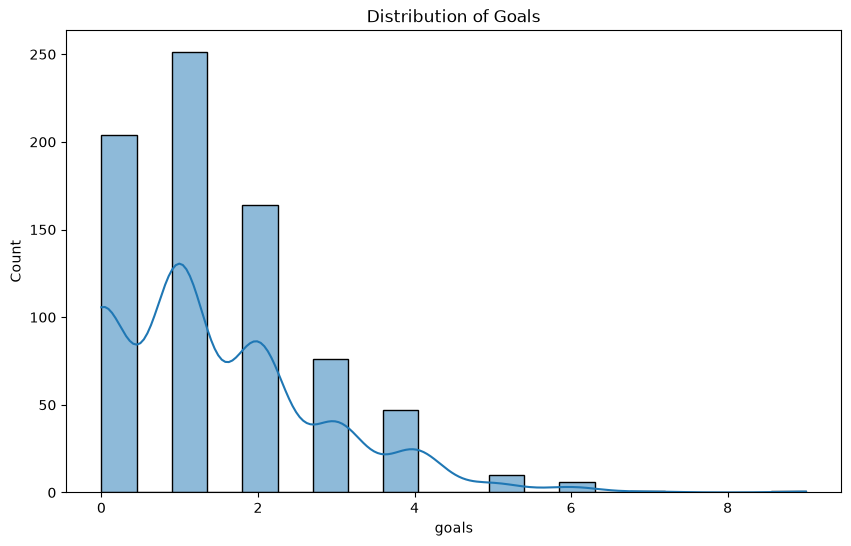

In [10]:
# Distribution of goals
plt.figure(figsize=(10, 6))

sns.histplot(df['goals'], bins=20, kde=True)
plt.title('Distribution of Goals')

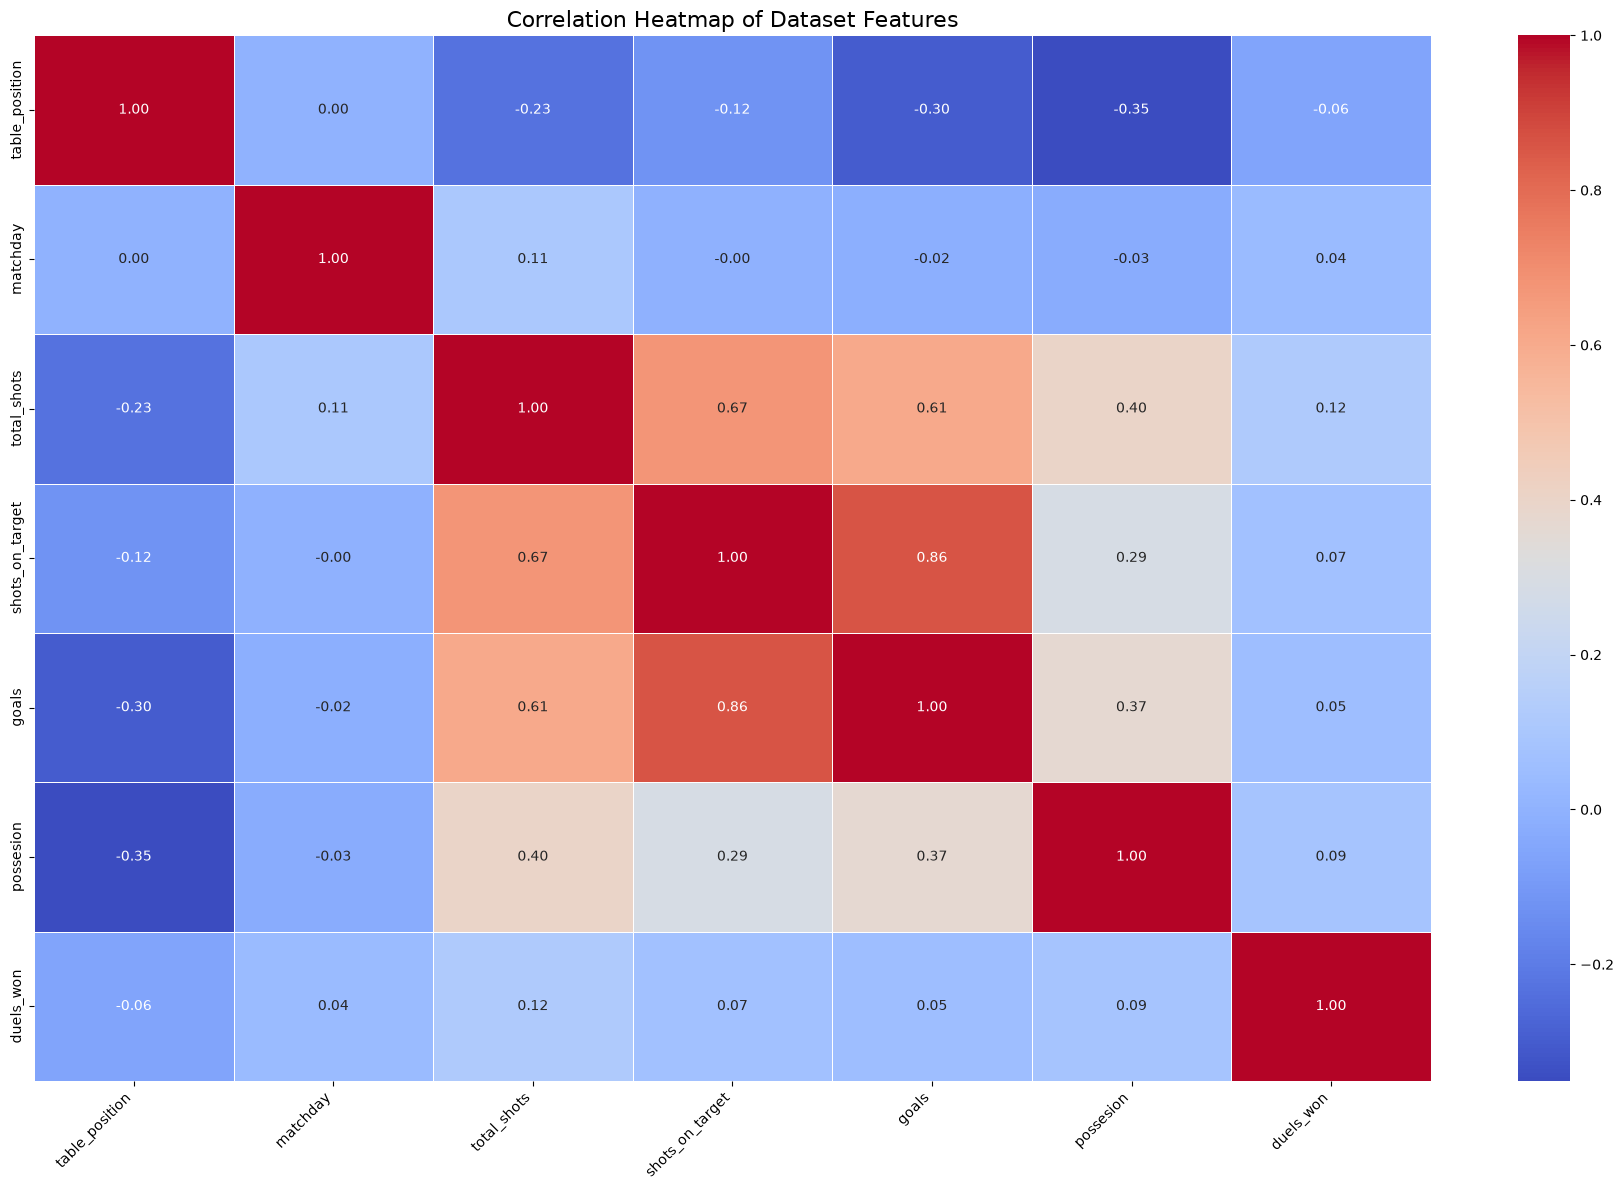

In [8]:
numeric_data = df.select_dtypes(include=['float64', 'int64'])

# Calculate the correlation matrix
correlation_matrix = numeric_data.corr()

# Set up the matplotlib figure
plt.figure(figsize=(18, 12))

# Draw the heatmap
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=True, fmt='.2f', linewidths=0.5)

# Title and labels
plt.title('Correlation Heatmap of Dataset Features', fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

# Show the plot
plt.show()